# 09: Mixed-Data Segmentation (2025 SHED)

Group respondents into household segments with K-prototypes, without using `financially_fragile`. The fragility rate of each segment is looked at only after the segments are built.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from kmodes.kprototypes import KPrototypes

RANDOM_STATE = 46796
K_VALUES = range(2, 9)
N_INIT = 4

## Load the modeling data

In [2]:
# Works whether Jupyter starts in notebooks/ or the project root
DATA_DIR = next(path for path in [Path("."), Path("data/processed"), Path("../data/processed")]
                if (path / "model_dataset_2025.csv").exists())

data = pd.read_csv(DATA_DIR / "model_dataset_2025.csv", low_memory=False)
with open(DATA_DIR / "model_dataset_2025_spec.json", encoding="utf-8") as f:
    spec = json.load(f)

TARGET = spec["target"]["column"]
WEIGHT = spec["weight"]
ID = spec["id"]

assert data[ID].notna().all() and data[ID].is_unique
assert data[TARGET].notna().all() and set(data[TARGET].unique()) == {0, 1}
assert np.isfinite(data[WEIGHT]).all() and (data[WEIGHT] > 0).all()
print(f"{len(data):,} respondents")

12,934 respondents


## Choose clustering features

Segments are built from a small set of financial-situation questions that every respondent was asked, so skip logic (`__NOT_ASKED__`) does not drive the clusters. Left out on purpose:

- The target and the EF (emergency-finance) module, so the segments do not just rediscover the label.
- Demographics (race, gender, age group, education, region), so we can later check whether segments line up with or cut across them.

Descriptions are taken from the [2025 SHED codebook](https://www.federalreserve.gov/consumerscommunities/files/SHED_2025codebook.pdf).

| Feature | Codebook question (shortened) |
|---|---|
| `B2` | How well are you managing financially these days? |
| `B3` | Compared to 12 months ago, are you better off, the same, or worse off financially? |
| `inc_4cat_50k` | Combined household income in the past 12 months (`I40`), grouped into 4 bands |
| `ppemploy` | Current employment status |
| `GH1` | Own home with a mortgage, own free and clear, pay rent, or neither |
| `FD3` | In the past month, which best describes the food eaten in your household? |
| `C2A` | Do you have at least one credit card (not debit or prepaid)? |
| `BNPL1` | In the past year, have you used a "Buy Now, Pay Later" service? |
| `BK1` | Do you (and/or spouse or partner) have a checking, savings, or money market account? |
| `K21_a` | Has a retirement savings account (401(k), IRA, Roth IRA) |
| `K21_b` | Has a defined-benefit pension through an employer |
| `K21_c` | Has stocks, bonds, ETFs, or mutual funds outside a retirement account |
| `K21_d` | Has a savings account, money market account, or CD |
| `K21_e` | Has cash value in a life insurance policy |
| `K21_f` | Has a business or real estate investment (other than primary residence) |
| `ppage`, `pphhsize` | Age and household size (numeric) |

In [3]:
SEGMENT_NUMERIC = ["ppage", "pphhsize"]
SEGMENT_CATEGORICAL = [
    "B2", "B3", "inc_4cat_50k", "ppemploy", "GH1", "FD3",
    "C2A", "BNPL1", "BK1",
    "K21_a", "K21_b", "K21_c", "K21_d", "K21_e", "K21_f",
]
SEGMENT_FEATURES = SEGMENT_NUMERIC + SEGMENT_CATEGORICAL

assert set(SEGMENT_FEATURES).issubset(data.columns)
assert not set(SEGMENT_FEATURES) & (set(spec["ef_module"]) | {TARGET})
assert data[SEGMENT_FEATURES].notna().all().all()
assert not (data[SEGMENT_CATEGORICAL] == "__NOT_ASKED__").any().any()

## Prepare the data

Numeric columns are standardized so age (in years) does not outweigh the categorical answers. Categorical answers stay as text labels; K-prototypes counts mismatches on them directly. `gamma` (the weight on the categorical part) is left at the `kmodes` default.

Segmentation uses all 12,934 respondents.

In [4]:
X = data[SEGMENT_FEATURES].copy()
numeric_mean = X[SEGMENT_NUMERIC].mean()
numeric_sd = X[SEGMENT_NUMERIC].std()
X[SEGMENT_NUMERIC] = (X[SEGMENT_NUMERIC] - numeric_mean) / numeric_sd

X_array = X.to_numpy(dtype=object)
CATEGORICAL_INDEX = [SEGMENT_FEATURES.index(col) for col in SEGMENT_CATEGORICAL]
weights = (data[WEIGHT] / data[WEIGHT].mean()).to_numpy()


def fit_segments(n_clusters, X_values=X_array, sample_weight=weights):
    model = KPrototypes(n_clusters=n_clusters, init="Cao", n_init=N_INIT,
                        random_state=RANDOM_STATE, n_jobs=-1)
    labels = model.fit_predict(X_values, categorical=CATEGORICAL_INDEX,
                               sample_weight=sample_weight)
    return model, labels

## Choose the number of segments

Fit K-prototypes for k = 2 to 8 and plot the cost: the weighted distance from each respondent to their segment's prototype. Cost always falls as k grows, so look for the "elbow" where adding a segment stops helping much. Very small segments are also a warning sign.

,cost,smallest segment (%)
k,,
2,48894.7,42.1
3,42704.4,30.5
4,39240.3,17.0
5,37344.7,15.4
6,35913.9,13.2
7,34295.4,8.9
8,33487.3,1.7


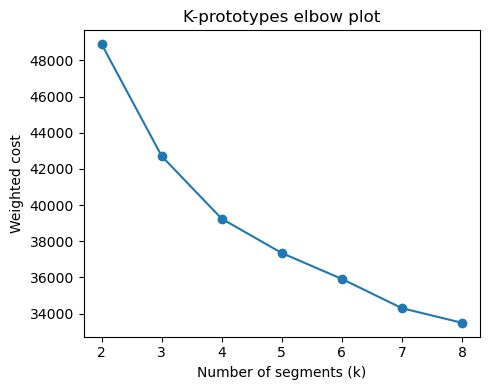

In [5]:
scan_rows = []
scan_labels = {}
for k in K_VALUES:
    model, labels = fit_segments(k)
    scan_labels[k] = labels
    shares = np.bincount(labels, weights=weights, minlength=k) / weights.sum()
    scan_rows.append({"k": k, "cost": model.cost_,
                      "smallest segment (%)": 100 * shares.min()})
scan = pd.DataFrame(scan_rows).set_index("k")
display(scan.round(1))

fig, ax = plt.subplots(figsize=(5, 4))
ax.plot(scan.index, scan["cost"], "o-")
ax.set(xlabel="Number of segments (k)", ylabel="Weighted cost",
       title="K-prototypes elbow plot")
fig.tight_layout()
plt.show()

## Fit final segments

Use k = 4. Cost falls steeply up to k = 4 and kind of slowdown after it (the elbow)

Segment numbers from K-prototypes are arbitrary, so segments are renumbered from lowest to highest fragility rate (1 = least fragile). The target is used only for this ordering and the profiles below, never in the clustering.

In [6]:
N_SEGMENTS = 4

final_segments, raw_labels = fit_segments(N_SEGMENTS)
data["raw_segment"] = raw_labels

# Renumber segments by weighted fragility rate
raw_rates = data.groupby("raw_segment").apply(
    lambda g: np.average(g[TARGET], weights=g[WEIGHT]), include_groups=False)
order = raw_rates.sort_values().index
relabel = {raw: new for new, raw in enumerate(order, start=1)}
data["segment"] = data["raw_segment"].map(relabel)
data["segment"].value_counts().sort_index()

segment
1    4613
2    4309
3    1808
4    2204
Name: count, dtype: int64

## Describe each segment

Population share and fragility rate are weighted with `weight_pop`. The prototype columns show the most common answer in each segment (for categoricals) and the weighted segment average (for age and household size).

In [7]:
summary_rows = []
for segment, group in data.groupby("segment"):
    w = group[WEIGHT]
    summary_rows.append({
        "segment": segment,
        "respondents": len(group),
        "population share (%)": 100 * w.sum() / data[WEIGHT].sum(),
        "fragile rate (%)": 100 * np.average(group[TARGET], weights=w),
        "mean age": np.average(group["ppage"], weights=w),
        "mean household size": np.average(group["pphhsize"], weights=w),
    })
summary = pd.DataFrame(summary_rows).set_index("segment")
overall_rate = 100 * np.average(data[TARGET], weights=data[WEIGHT])
print(f"Overall fragile rate: {overall_rate:.1f}%")
display(summary.round(1))

# Prototype answers, rows = features & columns = segments
centroids = pd.DataFrame(final_segments.cluster_centroids_, columns=SEGMENT_FEATURES)
centroids.index = [relabel[raw] for raw in range(N_SEGMENTS)]
centroids = centroids.sort_index()
# kmodes' internal numeric centers drift from the true weighted means,
# so show the same averages as the summary table
centroids["ppage"] = summary["mean age"].round(1)
centroids["pphhsize"] = summary["mean household size"].round(1)
prototypes = centroids.T
prototypes.columns.name = "segment"
display(prototypes)

Overall fragile rate: 36.9%


,respondents,population share (%),fragile rate (%),mean age,mean household size
segment,,,,,
1,4613,29.4,18.0,69.7,1.9
2,4309,35.2,24.7,45.8,2.9
3,1808,17.0,62.9,34.9,5.3
4,2204,18.4,66.2,32.1,2.0


segment,1,2,3,4
ppage,69.7,45.8,34.9,32.1
pphhsize,1.9,2.9,5.3,2.0
B2,Living comfortably,Doing okay,Doing okay,Just getting by
B3,About the same,About the same,About the same,About the same
inc_4cat_50k,"$100,000 or more","$100,000 or more","Less than $25,000","Less than $25,000"
ppemploy,Not working,Working full-time,Working full-time,Working full-time
GH1,Own your home free and clear (without a mortga...,Own your home with a mortgage or loan,Pay rent,Pay rent
FD3,Enough of the kinds of food we wanted to eat,Enough of the kinds of food we wanted to eat,"Enough, but not always the kinds of food we wa...","Enough, but not always the kinds of food we wa..."
C2A,Yes,Yes,Yes,Yes
BNPL1,No,No,No,No


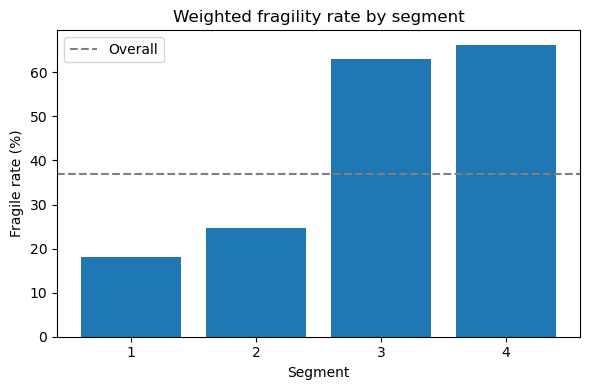

In [8]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(summary.index.astype(str), summary["fragile rate (%)"])
ax.axhline(overall_rate, linestyle="--", color="gray", label="Overall")
ax.set(xlabel="Segment", ylabel="Fragile rate (%)",
       title="Weighted fragility rate by segment")
ax.legend()
fig.tight_layout()
plt.show()

## Save outputs

Store each respondent's segment and the segment profiles in `outputs/task5/` so later notebooks (stability check, demographic comparison) can reuse them.

In [9]:
OUTPUT_DIR = Path("../outputs/task5") if Path("../data").exists() else Path("outputs/task5")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

data[[ID, "segment"]].to_csv(OUTPUT_DIR / "segments.csv", index=False)
summary.join(centroids).to_csv(OUTPUT_DIR / "segment_profiles.csv")
print(f"Saved segments for {len(data):,} respondents to {OUTPUT_DIR}")

Saved segments for 12,934 respondents to outputs/task5


## Test segment stability
